<a href="https://colab.research.google.com/github/ANANTHA1628/mesin-learning-/blob/main/tugas%20js%205%20.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

=== Hasil HDBSCAN pada Data Asli (64D) ===
Jumlah cluster: 8
Jumlah noise: 838
Adjusted Rand Index (ARI): 0.2831

=== Hasil HDBSCAN pada Data t-SNE (2D) ===
Jumlah cluster: 11
Jumlah noise: 83
Adjusted Rand Index (ARI): 0.8818



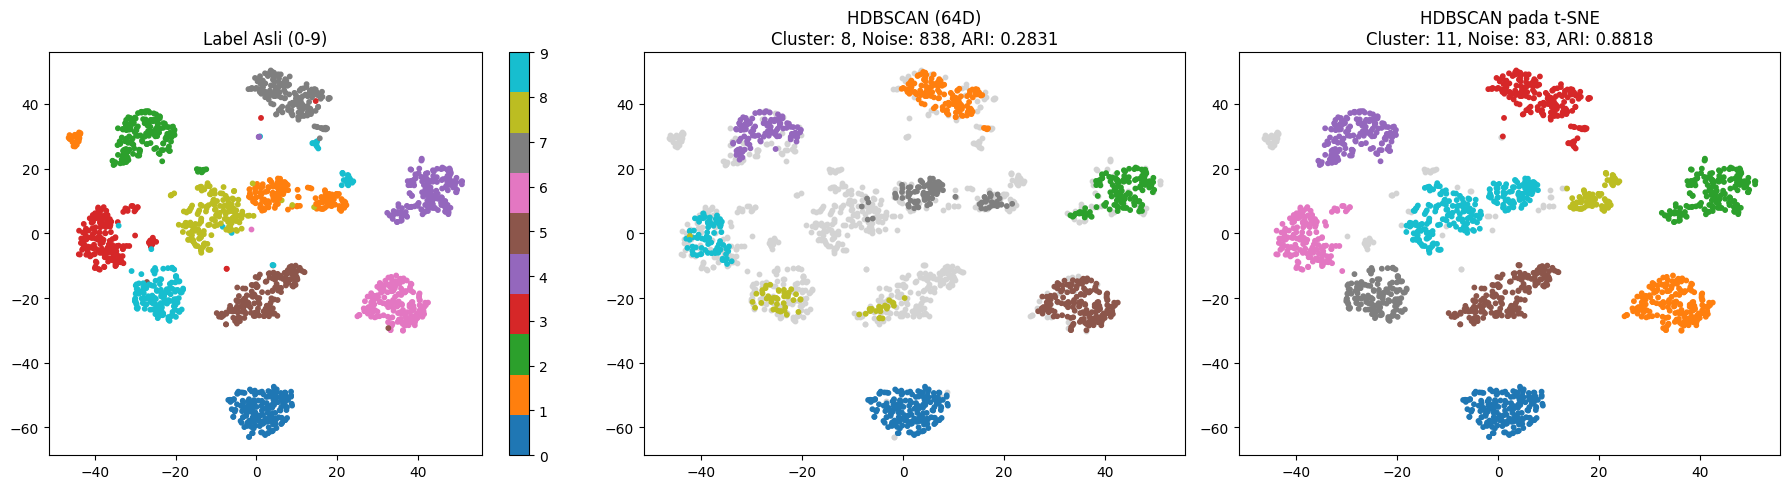

In [1]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.manifold import TSNE
from sklearn.metrics import adjusted_rand_score
from sklearn.cluster import HDBSCAN # Pastikan scikit-learn versi >= 1.3

# 1. Load Dataset Digits
digits = load_digits()
X = digits.data
y_true = digits.target

# 2. Reduksi Dimensi dengan t-SNE (untuk visualisasi dan clustering skenario 2)
tsne = TSNE(n_components=2, random_state=42)
X_tsne = tsne.fit_transform(X)

# =========================================================
# Skenario 1: HDBSCAN pada data asli (64-dimensi)
# =========================================================
clusterer_raw = HDBSCAN(min_samples=10, min_cluster_size=30)
y_pred_raw = clusterer_raw.fit_predict(X)

n_clusters_raw = len(set(y_pred_raw)) - (1 if -1 in y_pred_raw else 0)
n_noise_raw = list(y_pred_raw).count(-1)
ari_raw = adjusted_rand_score(y_true, y_pred_raw)

print("=== Hasil HDBSCAN pada Data Asli (64D) ===")
print(f"Jumlah cluster: {n_clusters_raw}")
print(f"Jumlah noise: {n_noise_raw}")
print(f"Adjusted Rand Index (ARI): {ari_raw:.4f}\n")

# =========================================================
# Skenario 2: HDBSCAN pada data hasil reduksi t-SNE (2-dimensi)
# =========================================================
clusterer_tsne = HDBSCAN(min_samples=10, min_cluster_size=30)
y_pred_tsne = clusterer_tsne.fit_predict(X_tsne)

n_clusters_tsne = len(set(y_pred_tsne)) - (1 if -1 in y_pred_tsne else 0)
n_noise_tsne = list(y_pred_tsne).count(-1)
ari_tsne = adjusted_rand_score(y_true, y_pred_tsne)

print("=== Hasil HDBSCAN pada Data t-SNE (2D) ===")
print(f"Jumlah cluster: {n_clusters_tsne}")
print(f"Jumlah noise: {n_noise_tsne}")
print(f"Adjusted Rand Index (ARI): {ari_tsne:.4f}\n")

# =========================================================
# 3. Visualisasi Hasil
# =========================================================
plt.figure(figsize=(18, 5))

# Plot 1: Label Asli (sebagai referensi)
plt.subplot(1, 3, 1)
scatter_true = plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=y_true, cmap='tab10', s=10)
plt.colorbar(scatter_true)
plt.title('Label Asli (0-9)')

# Plot 2: Hasil HDBSCAN Skenario 1 (diplot pada ruang t-SNE agar terlihat)
plt.subplot(1, 3, 2)
noise_mask_raw = (y_pred_raw == -1)
plt.scatter(X_tsne[noise_mask_raw, 0], X_tsne[noise_mask_raw, 1], c='lightgray', s=10, label='Noise')
scatter_raw = plt.scatter(X_tsne[~noise_mask_raw, 0], X_tsne[~noise_mask_raw, 1], c=y_pred_raw[~noise_mask_raw], cmap='tab10', s=10)
plt.title(f'HDBSCAN (64D)\nCluster: {n_clusters_raw}, Noise: {n_noise_raw}, ARI: {ari_raw:.4f}')

# Plot 3: Hasil HDBSCAN Skenario 2
plt.subplot(1, 3, 3)
noise_mask_tsne = (y_pred_tsne == -1)
plt.scatter(X_tsne[noise_mask_tsne, 0], X_tsne[noise_mask_tsne, 1], c='lightgray', s=10, label='Noise')
scatter_tsne = plt.scatter(X_tsne[~noise_mask_tsne, 0], X_tsne[~noise_mask_tsne, 1], c=y_pred_tsne[~noise_mask_tsne], cmap='tab10', s=10)
plt.title(f'HDBSCAN pada t-SNE\nCluster: {n_clusters_tsne}, Noise: {n_noise_tsne}, ARI: {ari_tsne:.4f}')

plt.tight_layout()
plt.show()